In [63]:
import sys
print(sys.version)

import pandas as pd
print("Pandas is working!")

3.14.2 (main, Aug 25 2026, 05:50:55) [Clang 23.0.0git (https:/github.com/llvm/llvm-project e5927fecf8a6ce89e1a4eac5b8
Pandas is working!


In [64]:
import sys
print("Python version:", sys.version)

import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


print("All libraries are working!")

Python version: 3.14.2 (main, Aug 25 2026, 05:50:55) [Clang 23.0.0git (https:/github.com/llvm/llvm-project e5927fecf8a6ce89e1a4eac5b8
Pandas version: 3.0.2
NumPy version: 2.4.6
All libraries are working!


In [65]:
# Check Pandas installation

print("Pandas object:", pd)
print("Pandas version:", getattr(pd, "__version__", "Unknown"))
print("Pandas location:", getattr(pd, "__file__", "Unknown"))

print("\nDoes read_csv exist?")
print(hasattr(pd, "read_csv"))

print("\nDoes DataFrame exist?")
print(hasattr(pd, "DataFrame"))

Pandas object: <module 'pandas' from '/lib/python3.14/site-packages/pandas/__init__.py'>
Pandas version: 3.0.2
Pandas location: /lib/python3.14/site-packages/pandas/__init__.py

Does read_csv exist?
True

Does DataFrame exist?
True


In [66]:
import pandas as pd

print("Pandas CSV function:", pd.read_csv)
print("Pandas is ready!")

Pandas CSV function: <function read_csv at 0x4ec28d8>
Pandas is ready!


In [67]:
import os

# Check current working directory
print("Current Working Directory:")
print(os.getcwd())

#Display available files
print("\nFiles in Current Directory:")
print(os.listdir())

Current Working Directory:
/drive/notebooks

Files in Current Directory:
['Retail_Sales_Dataset.csv', 'Retail_Sales_EDA_Project.ipynb', 'cpp-tiny-ray-tracer.ipynb', 'cpp-third-party-libs.ipynb', 'r.ipynb', 'Intro.ipynb', 'sqlite.ipynb', 'cpp.ipynb', 'Lorenz.ipynb', 'Mandelbrot.ipynb']


In [68]:
# Load the Retail Sales Dataset

df = pd.read_csv("Retail_Sales_Dataset.csv")

# Display first 5 records
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [69]:
# Check dataset dimensions

print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Number of Rows: 1000
Number of Columns: 9

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 54.8 KB


In [70]:
# Check missing values

print(df.isnull().sum())

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [71]:
# Convert Date column into datetime format

df['Date'] = pd.to_datetime(df['Date'])

# Check updated data types
print("Updated Data Types:")
print(df.dtypes)

# Display first 5 dates
print("\nFirst 5 Dates:")
print(df['Date'].head())

Updated Data Types:
Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object

First 5 Dates:
0   2023-11-24
1   2023-02-27
2   2023-01-13
3   2023-05-21
4   2023-05-06
Name: Date, dtype: datetime64[us]


In [72]:
# Calculate descriptive statistics

print("DESCRIPTIVE STATISTICS")

print("\nMean:")
print(df.select_dtypes(include='number').mean())

print("\nMedian:")
print(df.select_dtypes(include='number').median())

print("\nMode:")
print(df.select_dtypes(include='number').mode())

print("\nStandard Deviation:")
print(df.select_dtypes(include='number').std())

DESCRIPTIVE STATISTICS

Mean:
Transaction ID    500.500
Age                41.392
Quantity            2.514
Price per Unit    179.890
Total Amount      456.000
dtype: float64

Median:
Transaction ID    500.5
Age                42.0
Quantity            3.0
Price per Unit     50.0
Total Amount      135.0
dtype: float64

Mode:
     Transaction ID   Age  Quantity  Price per Unit  Total Amount
0                 1  43.0       4.0            50.0          50.0
1                 2  64.0       NaN             NaN           NaN
2                 3   NaN       NaN             NaN           NaN
3                 4   NaN       NaN             NaN           NaN
4                 5   NaN       NaN             NaN           NaN
..              ...   ...       ...             ...           ...
995             996   NaN       NaN             NaN           NaN
996             997   NaN       NaN             NaN           NaN
997             998   NaN       NaN             NaN           NaN
998           

In [73]:
# Check duplicate records

duplicate_count = df.duplicated().sum

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: <bound method Series.sum of 0      False
1      False
2      False
3      False
4      False
       ...  
995    False
996    False
997    False
998    False
999    False
Length: 1000, dtype: bool>


In [74]:
# Monthly Sales Analysis

# Extract month and year from Date
df['Month'] = df['Date'].dt.to_period('M')

# Calculate total monthly sales 
monthly_sales = df.groupby('Month')['Total Amount'].sum()

# Display monthly sales
print("MONTHLY SALES SUMMARY")
print(monthly_sales)

MONTHLY SALES SUMMARY
Month
2023-01    35450
2023-02    44060
2023-03    28990
2023-04    33870
2023-05    53150
2023-06    36715
2023-07    35465
2023-08    36960
2023-09    23620
2023-10    46580
2023-11    34920
2023-12    44690
2024-01     1530
Freq: M, Name: Total Amount, dtype: int64


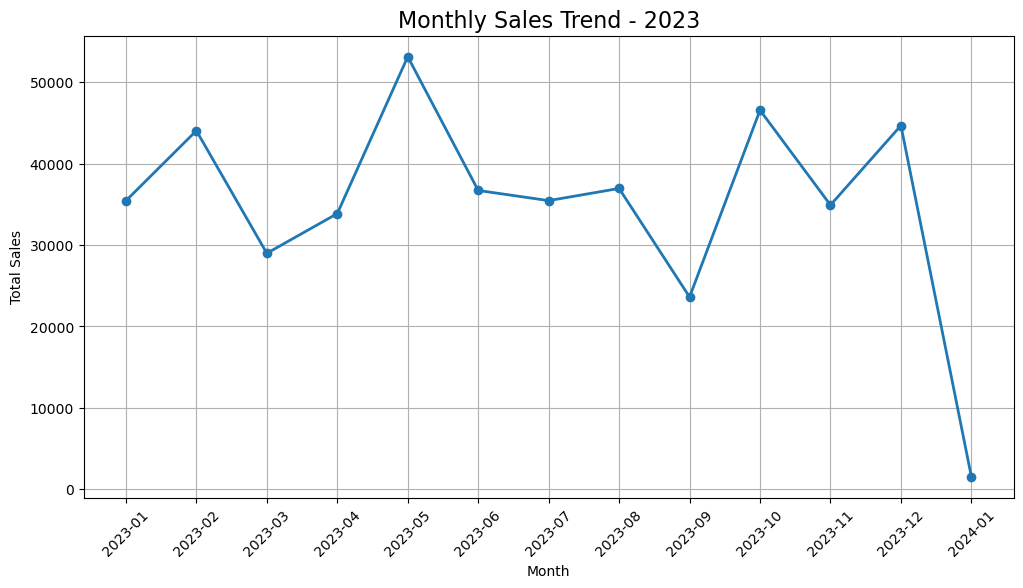

In [75]:
# Visualise Monthly Sales Trends

plt.figure(figsize=(12,6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Monthly Sales Trend - 2023', fontsize=16)
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

### Observation – Monthly Sales Trend

The monthly sales trend helps identify changes in sales performance throughout the year. It allows us to identify months with higher and lower sales and understand possible seasonal patterns.

The highest and lowest sales months will be identified from the chart.

In [ ]:
# Quarterly Sales Analysis

# Extract quarter from Date
df['Quarter'] = df['Date'].dt.to_period('Q')

# Calculate total sales for each quarter
quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

# Display quarterly sales
print("QUARTERLY SALES SUMMARY")
print(quarterly_sales)

In [ ]:
# Quarterly Sales Trend

plt.figure(figsize=(10,6))

plt.plot(
    quarterly_sales.index.astype(str),
    quarterly_sales.values,
    marker='o',
    linewidth=2
)

plt.title('Quarterly Sales Trend - 2023', fontsize=16)
plt.xlabel('Quarter')
plt.ylabel('Total Sales')
plt.grid(True)

plt.tight_layout()

### Observation – Quarterly Sales Analysis

Quarterly sales analysis helps us understand business performance across different periods of the year.

It helps identify:
- The quarter with the highest sales.
- The quarter with the lowest sales.
- Changes in sales performance between quarters.

These findings can help businesses plan inventory, marketing campaigns and sales strategies.

In [ ]:
# Group customer by age
bins =[0, 17, 25, 35, 45, 55, 100]
labels = ['Under 18', '18-25', '26-35', '36-45', '46-55', 'Above 55']

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)


# Count customers in each age group
age_group_counts = df['Age Group'].value_counts().sort_index()

print("CUSTOMER DISTRIBUTION BY AGE GROUP")
print(age_group_counts)

In [ ]:
plt.figure(figsize=(10, 6))

age_group_counts.plot(kind='bar')

plt.title('Customer Distribution by Age Group', fontsize=16)
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Observations – Age Group Distribution

- The chart shows the distribution of customers across different age groups.
- It helps identify the age groups that contribute most to retail transactions.
- The business can use this information to plan targeted marketing campaigns and product offers.

In [ ]:
gender_counts = df['Gender'].value_counts()

print("CUSTOMER DISTRIBUTION BY GENDER")
print(gender_counts)

print("\nGENDER DDISTRIBUTION IN PERCENTAGE")
print((gender_counts / len(df) * 100).round(2))

In [ ]:
plt.figure(figsize=(8,5))

gender_counts.plot(kind='bar')

plt.title('Customer Distribution by Gender', fontsize=16)
plt.xlabel('Gender')
plt.ylabel('Number of Customer')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Observations – Gender Distribution

- Female customers account for 51% of the transactions.
- Male customers account for 49% of the transactions.
- The distribution is almost equal between both genders.
- The business can develop marketing campaigns that appeal to both male and female customers.

In [ ]:
category_sales = df.groupby('Product Category')['Total Amount'].sum()

category_sales = category_sales.sort_values(ascending=False)

print("REVENUE BY PRODUCT CATEGORY")
print(category_sales)

In [ ]:
plt.figure(figsize=(9, 5))

category_sales.plot(kind='bar')

plt.title('Revenue by Product Category', fontsize=16)
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Observations – Revenue by Product Category

- Electronics generates the highest revenue of 156,905.
- Clothing generates revenue of 155,580, showing strong sales performance.
- Beauty generates the lowest revenue of 143,515.
- The revenue difference between the three categories is relatively small.
- The business should maintain strong stock levels across all three categories and explore opportunities to increase Beauty sales.

In [ ]:
category_quantity = df.groupby('Product Category')['Quantity'].sum()


category_quantity =category_quantity.sort_values(ascending=False)

print("QUANTITY SOLD PRODUCT CATEGORY")
print(category_quantity)

In [ ]:
plt.figure(figsize=(9,5))

category_quantity.plot(kind='bar')

plt.title('Quantity Sold by Product Category', fontsize=16)
plt.xlabel('Product category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Observations – Quantity Sold by Product Category

- The chart compares the total quantity sold across product categories.
- It helps identify which category has the highest and lowest unit sales.
- The business can use this information to plan inventory and product availability.

In [ ]:
# Select relevant numberical columns
numeric_data = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']]

# Calculate correlation
correlation_matrix = numeric_data.corr()

print("CORRELATION MATRIX")
print(correlation_matrix)

In [ ]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

### Observations – Correlation Heatmap

- Price per Unit and Total Amount show a strong positive correlation (0.85).
- Quantity and Total Amount show a moderate positive correlation (0.37).
- Age and Total Amount have a very weak negative correlation (-0.06).
- Age has almost no linear correlation with Quantity (-0.02).
- Price per Unit has the strongest positive relationship with Total Amount.

In [ ]:
gender_revenue = df.groupby('Gender')['Total Amount'].sum()

gender_revenue = gender_revenue.sort_values(ascending=False)

print("TOTAL REVENUE BY GENDER")
print(gender_revenue)

In [ ]:
plt.figure(figsize=(8, 5))

gender_revenue.plot(kind='bar')

plt.title('Revenue by Gender', fontsize=16)
plt.xlabel('Gender')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

### Observations – Revenue by Gender

- Female customers generate total revenue of 232,840.
- Male customers generate total revenue of 223,160.
- Female customers contribute slightly more revenue than male customers.
- The revenue contribution from both genders is relatively balanced.
- The business can continue targeting both customer groups through suitable marketing strategies.

## 8. Business Insights, Recommendations and Conclusion

### Key Business Insights

1. **Product Category Performance:** Electronics generated the highest revenue (156,905), followed by Clothing (155,580) and Beauty (143,515).

2. **Customer Gender Distribution:** Female customers accounted for 51% of transactions, while male customers accounted for 49%.

3. **Revenue by Gender:** Female customers generated 232,840 in revenue, compared with 223,160 from male customers.

4. **Correlation Analysis:** Price per Unit showed a strong positive correlation with Total Amount (0.85), while Quantity showed a moderate positive correlation (0.37).

5. **Customer Age:** The age-group analysis helps identify the customer age segments represented in the dataset.

### Business Recommendations

1. **Improve Category Performance:** Maintain strong inventory levels for Electronics and Clothing while exploring promotional strategies to increase Beauty category revenue.

2. **Target Both Customer Groups:** Since male and female customers contribute relatively balanced transactions and revenue, develop marketing campaigns that appeal to both groups.

3. **Optimise Pricing and Product Mix:** Analyse pricing and quantity patterns to understand which products and price ranges contribute most to revenue.

4. **Use Customer Demographics:** Develop age-specific offers and marketing campaigns based on the customer age-group distribution.

5. **Improve Inventory Planning:** Use monthly, quarterly and category-wise sales trends to plan stock availability and avoid overstocking or stock shortages.

### Conclusion

This Exploratory Data Analysis project provided useful insights into retail sales performance, customer demographics, product category revenue and relationships between numerical variables.

The analysis identified Electronics as the highest-revenue category and showed a strong positive relationship between Price per Unit and Total Amount.

These findings can help the business make better decisions about marketing, pricing, inventory management and customer targeting.

Overall, data analysis can support informed business decisions and help improve retail performance.
